# 01: Baseline LEGATO core (flat, no pooling yet)

In [1]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
d = np.load("../derived/sim_local_K6_w0.5_seed0.npz")
views = torch.tensor(d["views_unlab"])    # shape (K, 800, 100)
true_edges = d["true_edges"]              # shape (K, K), 1 where two views really share info
print(views.shape, true_edges.shape)
display(true_edges)
display(views)

torch.Size([6, 800, 100]) (6, 6)


array([[0., 1., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 1., 0., 0.],
       [0., 0., 1., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1.],
       [0., 0., 0., 0., 1., 0.]], dtype=float32)

tensor([[[ 0.0433, -0.0300, -0.0420,  ...,  0.0690,  0.0803, -0.0758],
         [ 0.1327, -0.0920, -0.1287,  ...,  0.2096,  0.2427, -0.2295],
         [-0.5645,  0.4153,  0.5512,  ..., -0.7696, -0.8296,  0.8074],
         ...,
         [ 0.0267, -0.0184, -0.0259,  ...,  0.0425,  0.0495, -0.0467],
         [ 0.4847, -0.3502, -0.4723,  ...,  0.6876,  0.7539, -0.7289],
         [-0.1796,  0.1248,  0.1742,  ..., -0.2816, -0.3247,  0.3076]],

        [[ 0.6398, -0.0140, -0.5712,  ...,  0.0817, -0.1855, -0.4024],
         [-0.5455,  0.0113,  0.4810,  ..., -0.0661,  0.1504,  0.3314],
         [ 0.9719, -0.0392, -0.9490,  ...,  0.2259, -0.4827, -0.8326],
         ...,
         [ 0.3283, -0.0063, -0.2841,  ...,  0.0368, -0.0842, -0.1896],
         [ 0.2966, -0.0056, -0.2561,  ...,  0.0330, -0.0756, -0.1704],
         [ 0.9138, -0.0286, -0.8687,  ...,  0.1660, -0.3660, -0.7026]],

        [[-0.9266, -0.9312, -0.4977,  ..., -0.9196,  0.9183, -0.8431],
         [-0.9924, -0.9932, -0.7312,  ..., -0

In [2]:
class ViewEncoder(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, out_dim)
        )

    def forward(self, x):
        return self.encoder(x)


enc = ViewEncoder(100, 64, 16)
print(enc(views[0]).shape)
print(sum(p.numel() for p in enc.parameters()))

torch.Size([800, 16])
7504


In [3]:
class MultiViewEncoder(nn.Module):
    def __init__(self, n_views, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.encoders = nn.ModuleList([ViewEncoder(input_dim, hidden_dim, output_dim) for i in range(n_views)])

    def forward(self, views):
        embeddings = [self.encoders[k](views[k]) for k in range(len(self.encoders))]
        return torch.stack(embeddings, dim=1)

multi= MultiViewEncoder(6, 100, 64, 16)
H = multi(views)
print(H.shape)

torch.Size([800, 6, 16])


In [4]:
import torch.nn.functional as F


class GraphLearner(nn.Module):
    def __init__(self, embed_dim, project_dim, threshold):
        super().__init__()
        self.learner = nn.Sequential(
            nn.Linear(embed_dim, project_dim),
            nn.LeakyReLU()
        )
        self.threshold = threshold

    def forward(self, h):
        h_learned = self.learner(h)
        h_learned = F.normalize(h_learned, dim=2)
        A = h_learned @ h_learned.transpose(dim0=1, dim1=2)
        A = A.abs()
        A = torch.where(A<self.threshold, torch.zeros_like(A), A)
        return A, h_learned


gl = GraphLearner(16, 16, 0.1)
A, h_learned = gl(H)
print(A.shape)
print(A[0])

torch.Size([800, 6, 6])
tensor([[1.0000, 0.8848, 0.7427, 0.6000, 0.7071, 0.8060],
        [0.8848, 1.0000, 0.5543, 0.5765, 0.7812, 0.6478],
        [0.7427, 0.5543, 1.0000, 0.6089, 0.5624, 0.5559],
        [0.6000, 0.5765, 0.6089, 1.0000, 0.7358, 0.2840],
        [0.7071, 0.7812, 0.5624, 0.7358, 1.0000, 0.6659],
        [0.8060, 0.6478, 0.5559, 0.2840, 0.6659, 1.0000]],
       grad_fn=<SelectBackward0>)


In [5]:
A_norm = F.normalize(A, dim=-1, p=1)
print(A_norm.sum(dim=-1)[0]) 
Z = A_norm @ H
print(Z.shape)

class MultiViewDecoder(nn.Module):
    def __init__(self, n_views, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.decoders = nn.ModuleList([
            # same MLP class as the encoder with the sizes reversed (16 -> 100); one decoder per view, each with its own weights
            ViewEncoder(input_dim, hidden_dim, output_dim) for k in range(n_views)
        ])

    def forward(self, z):
        embeddings = [self.decoders[k](z[:, k]) for k in range(len(self.decoders))]
        return torch.stack(embeddings, dim=0)

decoder = MultiViewDecoder(6, 16, 64, 100)
recon = decoder(Z)
loss = F.mse_loss(recon, views)
print(recon.shape, loss.item())

tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
       grad_fn=<SelectBackward0>)
torch.Size([800, 6, 16])
torch.Size([6, 800, 100]) 0.5266318321228027


In [6]:
class LegatoMini(nn.Module):
    def __init__(self, n_views, input_dim, hidden_dim, output_dim, embed_dim, threshold):
        super().__init__()
        self.encoder = MultiViewEncoder(n_views, input_dim, hidden_dim, output_dim)
        self.learner = GraphLearner(embed_dim, embed_dim, threshold)
        self.decoder = MultiViewDecoder(n_views, embed_dim, hidden_dim, input_dim)

    def forward(self, views):
        H = self.encoder(views)
        A, h_proj = self.learner(H)
        A_norm = F.normalize(A, dim=-1, p=1)
        Z = A_norm @ H
        recon = self.decoder(Z)
        return recon, A, h_proj

In [7]:
EPOCHS = 200
torch.manual_seed(0)
model = LegatoMini(6, 100, 64, 16, 16, 0.1)
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)
for epoch in range(EPOCHS):
    optimizer.zero_grad()
    recon, A, h_proj = model(views)
    loss = F.mse_loss(recon, views)
    loss.backward()
    optimizer.step()
    if epoch % 20 == 0: print(epoch, loss.item())

0 0.5219438672065735
20 0.16850218176841736


40 0.01970822736620903
60 0.006705996114760637


80 0.003946559503674507
100 0.003073351224884391


120 0.0026427307166159153
140 0.0022210022434592247


160 0.0018202642677351832
180 0.001495396951213479


AUROC = 0.833  (30 wins out of 36 true-vs-false comparisons)


,pair,truth,learned
1,"(3,5)",-,0.7034
2,"(4,5)",TRUE,0.1994
3,"(2,3)",TRUE,0.1921
4,"(2,5)",-,0.1461
5,"(1,5)",-,0.0204
6,"(0,2)",-,0.0070
7,"(0,1)",TRUE,0.0040
8,"(0,3)",-,0.0036
9,"(1,3)",-,0.0023
10,"(1,2)",-,0.0015


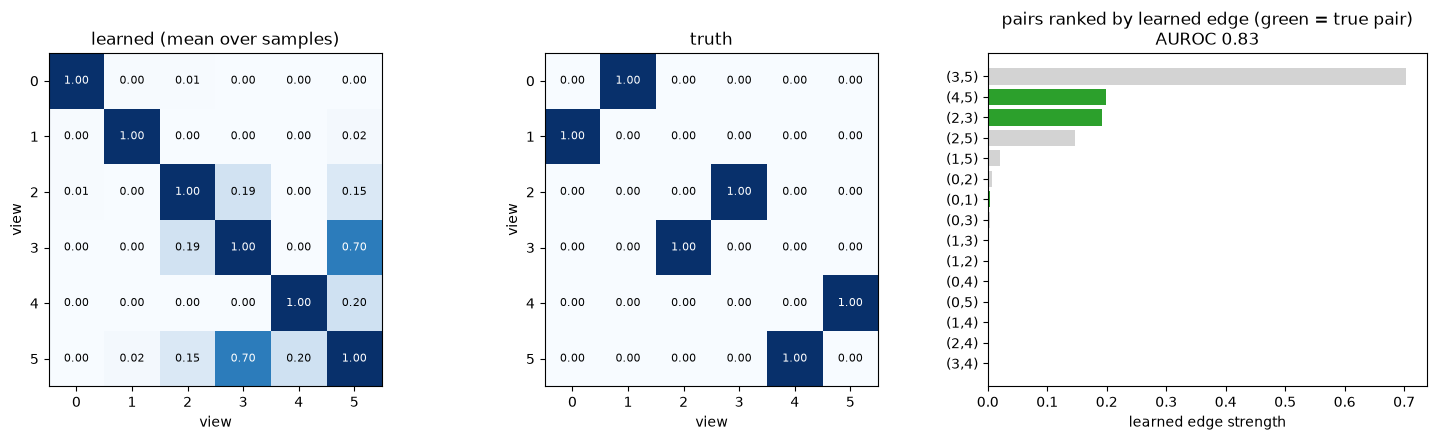

In [8]:
from sklearn.metrics import roc_auc_score
import pandas as pd

A_mean = A.mean(0).detach().numpy()          # (6, 6): average edge strength over the 800 samples
iu = np.triu_indices(6, k=1)                 # addresses of the 15 distinct pairs (above the diagonal)
truth, learned = true_edges[iu], A_mean[iu]  # two flat lists of 15, same pair order
auroc = roc_auc_score(truth, learned)

# AUROC by hand: every (true pair, false pair) comparison, did the true pair score higher?
pos, neg = learned[truth == 1], learned[truth == 0]
wins = sum((p > n) + 0.5 * (p == n) for p in pos for n in neg)
print(f"AUROC = {auroc:.3f}  ({wins:.0f} wins out of {len(pos) * len(neg)} true-vs-false comparisons)")

# the 15 pairs, ranked by learned edge strength (rank 1 = strongest edge)
df = pd.DataFrame({
    "pair": [f"({r},{c})" for r, c in zip(*iu)],
    "truth": np.where(truth == 1, "TRUE", "-"),
    "learned": learned.round(4),
}).sort_values("learned", ascending=False).reset_index(drop=True)
df.index += 1
display(df)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, M, title in [(ax[0], A_mean, "learned (mean over samples)"), (ax[1], true_edges, "truth")]:
    a.imshow(M, vmin=0, vmax=1, cmap="Blues")
    for i in range(6):
        for j in range(6):
            a.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8,
                   color="white" if M[i, j] > 0.6 else "black")
    a.set_title(title); a.set_xticks(range(6)); a.set_yticks(range(6))
    a.set_xlabel("view"); a.set_ylabel("view")

rev = df.iloc[::-1]                           # barh draws bottom-up, so reverse to put rank 1 on top
ax[2].barh(rev["pair"], rev["learned"],
           color=["tab:green" if t == "TRUE" else "lightgrey" for t in rev["truth"]])
ax[2].set_title(f"pairs ranked by learned edge (green = true pair)\nAUROC {auroc:.2f}")
ax[2].set_xlabel("learned edge strength")
plt.tight_layout(); plt.show()


,"(0,2)","(0,3)","(0,4)","(0,5)","(1,2)","(1,3)","(1,4)","(1,5)","(2,4)","(2,5)","(3,4)","(3,5)",wins
"(0,1)",LOSS,win,win,win,win,win,win,LOSS,win,LOSS,win,LOSS,8
"(2,3)",win,win,win,win,win,win,win,win,win,win,win,LOSS,11
"(4,5)",win,win,win,win,win,win,win,win,win,win,win,LOSS,11


total wins = 30 / 36  ->  AUROC = 0.833


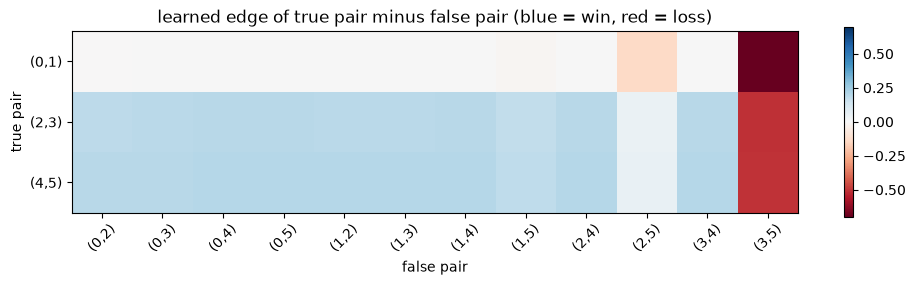

In [9]:
# All 36 true-vs-false comparisons behind the AUROC.
# Rows = the 3 true pairs, columns = the 12 false pairs.
# Cell = the learned edge of the TRUE pair minus the learned edge of the FALSE pair; > 0 means the true pair wins.
pairs = [f"({r},{c})" for r, c in zip(*iu)]
true_names  = [p for p, t in zip(pairs, truth) if t == 1]
false_names = [p for p, t in zip(pairs, truth) if t == 0]

diff = pd.DataFrame(pos[:, None] - neg[None, :], index=true_names, columns=false_names)
wins_grid = (diff > 0).replace({True: "win", False: "LOSS"})
wins_grid["wins"] = (diff > 0).sum(axis=1)       # how many of the 12 false pairs each true pair beats
display(wins_grid)
print(f"total wins = {int((diff > 0).sum().sum())} / {diff.size}  ->  AUROC = {(diff > 0).sum().sum() / diff.size:.3f}")

# the same grid, but showing the size of the gap (bluer = true pair wins by more, red = loses)
fig, ax = plt.subplots(figsize=(10, 2.6))
im = ax.imshow(diff.values, cmap="RdBu", vmin=-abs(diff.values).max(), vmax=abs(diff.values).max())
ax.set_xticks(range(len(false_names))); ax.set_xticklabels(false_names, rotation=45)
ax.set_yticks(range(len(true_names)));  ax.set_yticklabels(true_names)
ax.set_xlabel("false pair"); ax.set_ylabel("true pair")
ax.set_title("learned edge of true pair minus false pair (blue = win, red = loss)")
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()


In [10]:
import math



def _info_nce(a, b, temperature=0.1):
    a = F.normalize(a, dim=1)
    b = F.normalize(b, dim=1)
    S = a@b.T / temperature
    labels = torch.arange(a.shape[0])
    return F.cross_entropy(S, labels)



def info_nce_losses(embedding):
    losses = []
    n_views = embedding.shape[1]

    for i in range(n_views):
        for j in range(i+1, n_views):
            view_a = embedding[:,i] 
            view_b = embedding[:,j]
            loss_ij = _info_nce(view_a, view_b)
            losses.append([i,j,loss_ij])

    return losses

def avg_losses(paired_losses):
    return torch.stack([loss for i, j, loss in paired_losses]).mean()


In [11]:
EPOCHS = 200
lam = 1

torch.manual_seed(0)
model = LegatoMini(6, 100, 64, 16, 16, 0.1)
optimizer = torch.optim.Adam(model.parameters(), lr = 0.001)
for epoch in range(EPOCHS):
    optimizer.zero_grad()
    recon, A, h_proj = model(views)
    L = info_nce_losses(h_proj)
    loss_contrast = avg_losses(L)
    loss_recon = F.mse_loss(recon, views)
    loss = loss_recon + lam * loss_contrast
    loss.backward()
    optimizer.step()
    if epoch % 20 == 0: print(epoch, round(loss_recon.item(), 4), round(loss_contrast.item(), 3))

0 0.5219 6.733


20 0.2773 6.676


40 0.0499 6.674


60 0.0202 6.67


80 0.0107 6.667


100 0.007 6.666


120 0.0054 6.665


140 0.0044 6.664


160 0.0037 6.664


180 0.0032 6.664


In [12]:
with torch.no_grad():
    recon, A, h_proj = model(views)
    L = info_nce_losses(h_proj)

true_set = {(0, 1), (2, 3), (4, 5)}
t = [l.item() for i, j, l in L if (i, j) in true_set]
f = [l.item() for i, j, l in L if (i, j) not in true_set]
print("true pairs :", np.round(t, 3), " mean", round(np.mean(t), 3))
print("false pairs:", " mean", round(np.mean(f), 3))
print("chance:", round(math.log(800), 3), "  ceiling for true pairs ≈", round(math.log(800) - 0.144, 3))


true pairs : [6.542 6.527 6.684]  mean 6.585
false pairs:  mean 6.683
chance: 6.685   ceiling for true pairs ≈ 6.541


In [13]:
auroc_base = auroc
A_mean_c = A.mean(0).detach().numpy()
auroc_con = roc_auc_score(true_edges[iu], A_mean_c[iu])
print(f"edge-recovery AUROC, baseline: {auroc_base:.3f} | with contrastive loss: {auroc_con:.3f}")

edge-recovery AUROC, baseline: 0.833 | with contrastive loss: 1.000
